# Unidad 1 — Modelos no paramétricos

**Módulo 6: Modelos Avanzados de IA y Aplicaciones Económicas — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 13-11-2026 (2 horas) · Contenidos 1.1 a 1.5

Esta unidad es un **repaso con otra mirada**. En el Módulo 3 aprendimos a usar KNN, árboles y Random Forest; en el Módulo 5 llevamos el Random Forest a las series de tiempo. Hoy los ponemos uno al lado del otro para responder una sola pregunta: **¿qué modelo escoger y por qué?**

Todos estos modelos se llaman **no paramétricos** porque no suponen una fórmula fija (como la recta de una regresión): dejan que los datos decidan la forma de la respuesta. Eso los hace flexibles y también fáciles de sobreajustar.

## El caso que nos acompaña todo el módulo

Un banco emisor de tarjetas quiere saber, en septiembre, **qué clientes no van a pagar en octubre**. Es el conjunto *Default of Credit Card Clients* (30 000 clientes), que ya apareció en el proyecto final del Módulo 3. Lo usaremos en las Unidades 1 a 4: hoy con vecinos y árboles, después con Bayes y con redes neuronales, **siempre con la misma partición**, para que los números se puedan comparar.

## Objetivos de la unidad

Al terminar deberías poder explicar, con tus propias palabras:

- cómo decide KNN y por qué hay que **escalar** antes de medir distancias;
- qué es un **kernel**: vecinos que pesan según su cercanía;
- cómo decide un árbol y por qué un bosque lo mejora;
- la diferencia entre **bagging** (muchos modelos independientes que votan) y **boosting** (modelos en fila que corrigen al anterior);
- cuándo conviene cada método.

## Ruta de la unidad

| Parte | Contenido | Qué haremos | Herramienta |
|---|---|---|---|
| 1 | — | Mirar los datos, separar Train / Validation / Test y fijar la línea base | `pandas`, `train_test_split` |
| 2 | 1.1 | KNN a mano con 6 clientes y después con 18 000 | `KNeighborsClassifier` |
| 3 | 1.2 | De vecinos que votan a vecinos que pesan: el kernel | `weights='distance'`, `SVC` |
| 4 | 1.3 | Árbol de decisión y Random Forest | `DecisionTreeClassifier`, `RandomForestClassifier` |
| 5 | 1.4 | Bagging frente a boosting, primero a mano | `BaggingClassifier`, `GradientBoostingClassifier` |
| 6 | 1.5 | Comparación y guía de elección | — |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib scikit-learn

In [2]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'impago_tarjetas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /home/claude/m6/datos


# 0. Librerías

Todo viene de **scikit-learn**, la librería del Módulo 3. No hay nada nuevo que instalar.

| Herramienta | Para qué |
|---|---|
| `train_test_split` | separar Train, Validation y Test |
| `StandardScaler` + `make_pipeline` | escalar las variables **dentro** del modelo, sin fuga de información |
| `KNeighborsClassifier` | vecinos más cercanos |
| `SVC` | máquina de vectores de soporte con kernel (Módulo 3, Día 3) |
| `DecisionTreeClassifier`, `RandomForestClassifier` | árbol y bosque |
| `BaggingClassifier`, `GradientBoostingClassifier` | las dos formas de combinar modelos |
| `roc_auc_score`, `f1_score`, ... | métricas |

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

# 1. Los datos y la línea base

## 1.1 Mirar antes de modelar

Cada fila es un cliente. Las columnas describen lo que el banco sabía **en septiembre**:

| Grupo | Columnas | Significado |
|---|---|---|
| Perfil | `limite_credito`, `sexo`, `educacion`, `estado_civil`, `edad` | cupo de la tarjeta (en dólares taiwaneses, NT$) y datos del cliente |
| Atrasos | `atraso_sep`, `atraso_ago`, ..., `atraso_abr` | meses de atraso en cada uno de los últimos 6 meses (−2, −1 y 0 significan "al día"; 2 significa "dos meses de atraso") |
| Facturas | `factura_sep`, ..., `factura_abr` | saldo facturado cada mes |
| Pagos | `pago_sep`, ..., `pago_abr` | cuánto pagó cada mes |
| **Objetivo** | `impago` | 1 si **no pagó en octubre**, 0 si pagó |

In [4]:
datos = pd.read_csv(DATA_DIR / 'impago_tarjetas.csv')
print('Filas y columnas:', datos.shape)
datos.head()

Filas y columnas: (30000, 25)


,id,limite_credito,sexo,educacion,estado_civil,edad,atraso_sep,atraso_ago,atraso_jul,atraso_jun,...,factura_jun,factura_may,factura_abr,pago_sep,pago_ago,pago_jul,pago_jun,pago_may,pago_abr,impago
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
# ¿Qué proporción de clientes no pagó? Esta cifra es la "tasa base" y la usaremos todo el módulo.
print('Tasa de impago:', round(datos['impago'].mean(), 4))

# ¿Cambia la tasa de impago según el atraso de septiembre?
resumen = datos.groupby('atraso_sep')['impago'].agg(clientes='count', tasa_impago='mean').round(3)
resumen

Tasa de impago: 0.2212


,clientes,tasa_impago
atraso_sep,,
-2,2759,0.132
-1,5686,0.168
0,14737,0.128
1,3688,0.339
2,2667,0.691
3,322,0.758
4,76,0.684
5,26,0.500
6,11,0.545


**Qué obtuvimos:**

- **22 de cada 100 clientes no pagan.** Es un problema desbalanceado: un modelo que diga "todos pagan" acierta el 78 % de las veces sin haber aprendido nada. Por eso la exactitud sola no sirve.
- El atraso de septiembre separa muchísimo: entre los clientes al día (0 o menos) impaga entre el 13 % y el 17 %; con 1 mes de atraso, el 34 %; **con 2 meses de atraso, el 69 %**.

Esa última observación nos da una regla de negocio muy simple, que será nuestra línea base.

## 1.2 Train, Validation y Test

A diferencia de las series del Módulo 5, aquí **no hay orden temporal entre filas**: cada cliente es independiente, así que la partición aleatoria sí es correcta.

- **Train (60 %)**: para que los modelos aprendan.
- **Validation (20 %)**: para comparar modelos y elegir hiperparámetros.
- **Test (20 %)**: se guarda. Lo abriremos **una sola vez, en la Unidad 4**, con todos los modelos del módulo.

In [6]:
datos = pd.read_csv(DATA_DIR / 'impago_tarjetas.csv')

# X: lo que sabemos del cliente en septiembre · y: si no pagó en octubre (1 = impago)
X = datos.drop(columns=['id', 'impago'])
y = datos['impago']

# La misma partición en todo el módulo (misma semilla): 60 % Train, 20 % Validation, 20 % Test.
# stratify=y mantiene el 22 % de impagos en las tres partes.
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print('Train:', X_train.shape, '· Validation:', X_val.shape, '· Test:', X_test.shape)
print('Tasa de impago -> Train:', round(y_train.mean(), 3), '· Validation:', round(y_val.mean(), 3), '· Test:', round(y_test.mean(), 3))

Train: (18000, 23) · Validation: (6000, 23) · Test: (6000, 23)
Tasa de impago -> Train: 0.221 · Validation: 0.221 · Test: 0.221


## 1.3 Las métricas y la línea base

Usaremos cuatro números, todos del Módulo 3:

| Métrica | Pregunta que responde |
|---|---|
| **Exactitud** | ¿qué fracción de clientes clasifiqué bien? (engañosa con datos desbalanceados) |
| **Precisión** | de los que marqué como impago, ¿cuántos lo eran? |
| **Sensibilidad (recall)** | de los que de verdad impagaron, ¿a cuántos detecté? |
| **AUC** | si tomo un cliente que impagó y uno que pagó, ¿con qué frecuencia el modelo le da más riesgo al primero? 0.5 = al azar, 1 = perfecto. No depende del umbral |

Y dos líneas base:

1. **"Todos pagan"**: la más ingenua.
2. **Regla del atraso**: marcar como impago a quien tenga 2 o más meses de atraso en septiembre.

In [7]:
resultados = {}   # aquí iremos guardando cada modelo para la comparación final

def medir(nombre, y_real, prediccion, puntaje, segundos=0.0):
    """Calcula las métricas en Validation y las guarda en 'resultados'."""
    resultados[nombre] = {
        'Exactitud': accuracy_score(y_real, prediccion),
        'Precisión': precision_score(y_real, prediccion, zero_division=0),
        'Sensibilidad': recall_score(y_real, prediccion),
        'F1': f1_score(y_real, prediccion),
        'AUC': roc_auc_score(y_real, puntaje),
        'Segundos': segundos,
    }

# Línea base 1: todos pagan (predicción 0 para todos; puntaje constante -> AUC 0.5)
medir('Base: todos pagan', y_val, np.zeros(len(y_val)), np.zeros(len(y_val)))

# Línea base 2: impago si tiene 2 o más meses de atraso en septiembre
regla = (X_val['atraso_sep'] >= 2).astype(int)
medir('Base: atraso de 2+ meses', y_val, regla, X_val['atraso_sep'])

pd.DataFrame(resultados).T.round(3)

,Exactitud,Precisión,Sensibilidad,F1,AUC,Segundos
Base: todos pagan,0.779,0.000,0.000,0.00,0.500,0.0
Base: atraso de 2+ meses,0.816,0.683,0.313,0.43,0.683,0.0


**Qué obtuvimos:**

- "Todos pagan" tiene 78 % de exactitud y **0 de sensibilidad**: no detecta a nadie. Inútil para el banco.
- La regla del atraso, con una sola columna y sin entrenar nada, llega a **82 % de exactitud**, detecta al **31 %** de los que impagan y acierta en el **68 %** de sus alertas. Su AUC es 0.68.

**Esta regla es lo que hay que superar.** Como el PM12 en el Módulo 5: si un modelo complejo no le gana a una regla que cabe en una línea, no vale la pena.

## 1.4 Una función para evaluar cualquier modelo

Todos los modelos de scikit-learn se usan igual: `fit` para entrenar, `predict` para clasificar y `predict_proba` para obtener la probabilidad. Escribimos una sola función y la reutilizamos.

In [8]:
def evaluar(nombre, modelo, X_entrena=X_train, y_entrena=y_train):
    """Entrena con Train, mide en Validation y guarda el resultado. Devuelve el modelo entrenado."""
    inicio = time.time()
    modelo.fit(X_entrena, y_entrena)

    # Puntaje de riesgo: probabilidad de impago (o la distancia a la frontera, en SVM)
    if hasattr(modelo, 'predict_proba'):
        puntaje_val = modelo.predict_proba(X_val)[:, 1]
        puntaje_train = modelo.predict_proba(X_entrena)[:, 1]
    else:
        puntaje_val = modelo.decision_function(X_val)
        puntaje_train = modelo.decision_function(X_entrena)

    medir(nombre, y_val, modelo.predict(X_val), puntaje_val, time.time() - inicio)
    print(f'{nombre:38s} AUC Train = {roc_auc_score(y_entrena, puntaje_train):.3f} · AUC Validation = {resultados[nombre]["AUC"]:.3f}')
    return modelo

# 2. KNN: dime con quién andas (1.1)

## 2.1 La idea

Para decidir si un cliente nuevo va a impagar, KNN busca a los **k clientes más parecidos** del entrenamiento y mira qué hicieron. Si la mayoría impagó, predice impago.

"Parecido" significa "cerca", y cerca se mide con la **distancia euclídea** (el teorema de Pitágoras):

$$d = \sqrt{(x_1 - x'_1)^2 + (x_2 - x'_2)^2}$$

Cada símbolo: $x_1$ y $x_2$ son las dos variables del cliente nuevo; $x'_1$ y $x'_2$, las del cliente con el que lo comparo.

## 2.2 A mano con 6 clientes

Seis clientes, dos variables: meses de atraso y límite de crédito (en miles). Llega un cliente nuevo con **2 meses de atraso y 200 mil de cupo**. ¿Impaga?

In [9]:
clientes = pd.DataFrame({
    'atraso': [0, 0, 2, 3, 0, 2],
    'limite_miles': [210, 190, 50, 120, 30, 260],
    'impago': [0, 0, 1, 1, 0, 1],
}, index=list('ABCDEF'))

nuevo = {'atraso': 2, 'limite_miles': 200}

# Distancia de cada cliente al nuevo, con las variables tal como vienen
clientes['distancia'] = np.sqrt((clientes['atraso'] - nuevo['atraso'])**2 +
                                (clientes['limite_miles'] - nuevo['limite_miles'])**2).round(1)
clientes.sort_values('distancia')

,atraso,limite_miles,impago,distancia
A,0,210,0,10.2
B,0,190,0,10.2
F,2,260,1,60.0
D,3,120,1,80.0
C,2,50,1,150.0
E,0,30,0,170.0


**Lectura:** los tres más cercanos son A, B y F. Dos de los tres pagaron, así que KNN con k = 3 diría **"paga"**.

Pero mira por qué A y B quedaron cerca: su cupo (210 y 190) se parece al del cliente nuevo (200). El atraso casi no cuenta: una diferencia de 2 meses de atraso pesa lo mismo que una diferencia de 2 mil en el cupo. **La variable con números grandes domina la distancia.**

## 2.3 El arreglo: escalar

Escalar es poner todas las variables en la misma unidad: "cuántas desviaciones estándar por encima o por debajo del promedio".

$$z = \frac{x - \text{media}}{\text{desviación estándar}}$$

In [10]:
# Escalamos cada columna con SU media y SU desviación (calculadas con los 6 clientes)
media = clientes[['atraso', 'limite_miles']].mean()
desviacion = clientes[['atraso', 'limite_miles']].std(ddof=0)

escalados = (clientes[['atraso', 'limite_miles']] - media) / desviacion
nuevo_escalado = (pd.Series(nuevo) - media) / desviacion
print('Cliente nuevo escalado:', nuevo_escalado.round(2).to_dict())

clientes['distancia_escalada'] = np.sqrt(((escalados - nuevo_escalado)**2).sum(axis=1)).round(2)
clientes.sort_values('distancia_escalada')

Cliente nuevo escalado: {'atraso': 0.69, 'limite_miles': 0.67}


,atraso,limite_miles,impago,distancia,distancia_escalada
F,2,260,1,60.0,0.71
D,3,120,1,80.0,1.26
B,0,190,0,10.2,1.65
A,0,210,0,10.2,1.65
C,2,50,1,150.0,1.79
E,0,30,0,170.0,2.61


**Lectura:** ahora los más cercanos son **F y D**, los dos con atraso, y después A o B (empatados). Dos de los tres vecinos impagaron: KNN con k = 3 dice **"impaga"**. La predicción cambió solo por escalar.

**Regla:** en todo modelo que mida distancias (KNN, kernels, SVM, K-Means, y más adelante las redes neuronales), **primero se escala**. Los árboles no lo necesitan, porque solo preguntan "¿mayor o menor que...?".

## 2.4 KNN con los 18 000 clientes

Usamos `make_pipeline(StandardScaler(), KNeighborsClassifier(k))`: el pipeline calcula la media y la desviación **solo con Train** y aplica esa misma escala a Validation. Así no hay fuga de información.

Primero comprobamos con datos reales lo que vimos a mano: KNN con y sin escalar.

In [11]:
evaluar('KNN k=25 sin escalar', KNeighborsClassifier(n_neighbors=25))
evaluar('KNN k=25', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)));

KNN k=25 sin escalar                   AUC Train = 0.727 · AUC Validation = 0.646


KNN k=25                               AUC Train = 0.803 · AUC Validation = 0.746


**Lectura:** sin escalar, el AUC en Validation es 0.65, **peor que la regla de una línea** (0.68): las facturas, que llegan a cientos de miles, tapan a los atrasos. Escalando sube a 0.75.

## 2.5 ¿Cuántos vecinos?

`k` es el hiperparámetro de KNN:

- **k pequeño**: cada cliente se compara con muy pocos. El modelo memoriza (con k = 1, cada cliente de Train es su propio vecino).
- **k grande**: se promedia sobre mucha gente y el modelo se vuelve suave; si k fuera 18 000, siempre respondería la tasa base.

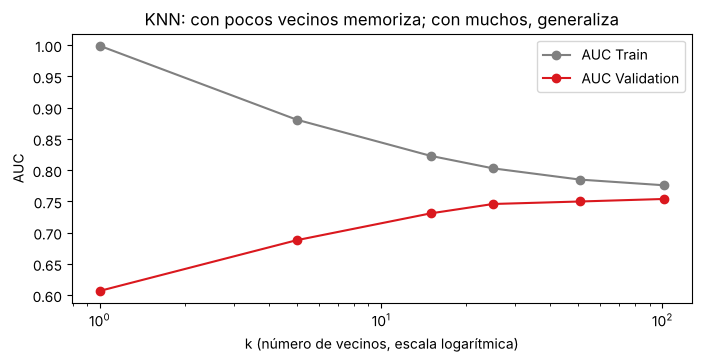

,AUC Train,AUC Validation
k,,
1,0.999,0.607
5,0.881,0.688
15,0.823,0.731
25,0.803,0.746
51,0.785,0.750
101,0.776,0.754


In [12]:
filas = []
for k in [1, 5, 15, 25, 51, 101]:
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    filas.append({
        'k': k,
        'AUC Train': roc_auc_score(y_train, modelo.predict_proba(X_train)[:, 1]),
        'AUC Validation': roc_auc_score(y_val, modelo.predict_proba(X_val)[:, 1]),
    })
curva_k = pd.DataFrame(filas).set_index('k').round(3)

ax = curva_k.plot(marker='o', figsize=(8, 3.5), color=['gray', '#DA181E'])
ax.set_xscale('log'); ax.set_xlabel('k (número de vecinos, escala logarítmica)'); ax.set_ylabel('AUC')
ax.set_title('KNN: con pocos vecinos memoriza; con muchos, generaliza')
plt.show()
curva_k

**Lectura: la curva del sobreajuste, otra vez.**

- Con **k = 1** el AUC en Train es prácticamente 1 (memoria perfecta) y en Validation 0.61: peor que la regla del atraso.
- Al subir k, Train baja y Validation sube hasta estabilizarse cerca de **0.75** entre k = 51 y k = 101.

Es la misma figura del `max_depth` del Random Forest (Módulo 5, Día 4): la distancia entre las dos curvas es lo que el modelo memorizó.

**Límites de KNN:** no entrena nada (guarda todos los datos), así que **predecir es lento** y empeora con muchas columnas, porque en muchas dimensiones todos los puntos quedan lejos de todos.

# 3. Métodos kernel: vecinos que pesan (1.2)

## 3.1 La idea

En KNN, el vecino número 1 y el número 25 votan igual, y el número 26 no vota nada. Es un corte brusco. Un **kernel** lo suaviza: **cada vecino pesa según su cercanía**. Muy cerca, pesa casi 1; lejos, pesa casi 0.

El kernel más usado es el **gaussiano** (la campana):

$$\text{peso} = e^{-\,d^2 / (2h^2)}$$

Cada símbolo: $d$ es la distancia al vecino; $h$ es el **ancho de banda**, que dice qué tan lejos llega la influencia (el papel que hacía k); $e$ es la constante 2.718.

Volvamos a los 6 clientes escalados y calculemos el peso de cada uno.

In [13]:
h = 1.0   # ancho de banda: prueba a cambiarlo por 0.5 o por 3

clientes['peso'] = np.exp(-clientes['distancia_escalada']**2 / (2 * h**2)).round(3)

# Probabilidad de impago del cliente nuevo = promedio de 'impago' ponderado por el peso
probabilidad = (clientes['peso'] * clientes['impago']).sum() / clientes['peso'].sum()
print('Probabilidad de impago con kernel gaussiano:', round(probabilidad, 3))

clientes[['atraso', 'limite_miles', 'impago', 'distancia_escalada', 'peso']].sort_values('distancia_escalada')

Probabilidad de impago con kernel gaussiano: 0.724


,atraso,limite_miles,impago,distancia_escalada,peso
F,2,260,1,0.71,0.777
D,3,120,1,1.26,0.452
B,0,190,0,1.65,0.256
A,0,210,0,1.65,0.256
C,2,50,1,1.79,0.201
E,0,30,0,2.61,0.033


**Lectura:** F, el más cercano, pesa 0.78; D, 0.45; A, B y C, entre 0.20 y 0.26; E casi no cuenta (0.03). Ya no hay que decidir "cuántos vecinos": **todos opinan, pero los cercanos opinan más fuerte**. La probabilidad de impago sale 0.72.

| | KNN | Kernel |
|---|---|---|
| ¿Quién opina? | los k más cercanos | todos |
| ¿Cuánto pesa cada uno? | igual | según su cercanía |
| Hiperparámetro | k | ancho de banda h |
| h pequeño / k pequeño | memoriza | memoriza |
| h grande / k grande | responde el promedio | responde el promedio |

## 3.2 En scikit-learn

Dos formas de usar la idea:

1. `KNeighborsClassifier(weights='distance')`: KNN en el que los vecinos pesan según 1/distancia.
2. `SVC(kernel='rbf')`: la **máquina de vectores de soporte** del Módulo 3. Usa el mismo kernel gaussiano (RBF), pero en lugar de preguntar a todos los clientes, aprende cuáles son los pocos clientes importantes (los vectores de soporte, cerca de la frontera) y solo les pregunta a ellos. Su `gamma` es el inverso del ancho de banda.

SVM tarda mucho con 18 000 filas, así que la entrenamos con una muestra de 5 000.

In [14]:
evaluar('KNN k=25 ponderado por distancia', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights='distance')))

# Muestra de 5 000 clientes de Train para SVM
X_muestra = X_train.sample(5000, random_state=42)
y_muestra = y_train.loc[X_muestra.index]
evaluar('SVM kernel RBF (5 000 clientes)', make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale')), X_muestra, y_muestra);

KNN k=25 ponderado por distancia       AUC Train = 1.000 · AUC Validation = 0.745


SVM kernel RBF (5 000 clientes)        AUC Train = 0.819 · AUC Validation = 0.728


**Lectura:**

- KNN ponderado: el AUC en Train es 1.000 (cada cliente está a distancia 0 de sí mismo y su peso es infinito) y en Validation queda igual que el KNN normal, 0.745. Ponderar no ayudó aquí.
- SVM con kernel queda en 0.73, por debajo de KNN en este problema. La comparación no es del todo justa: entrenó con 5 000 clientes y no con 18 000, porque su tiempo de entrenamiento crece muy rápido con el número de filas.

**Para recordar:** kernel = "parecido medido con una campana". Es la misma idea que KNN, con pesos suaves. Volveremos a ver esta idea de "sumar entradas con pesos" en la neurona de la Unidad 3.

# 4. Árbol de decisión y Random Forest (1.3)

## 4.1 Un árbol: preguntas de sí o no

En el Módulo 5 vimos el árbol como el juego de "adivina quién". Aquí las hojas no predicen un promedio sino una **proporción de impagos**. Entrenamos un árbol que solo puede hacer dos preguntas seguidas, para poder leerlo.

In [15]:
arbol_pequeno = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)

# Las reglas, en texto. 'weights' muestra [clientes que pagaron, clientes que impagaron] en cada hoja
print(export_text(arbol_pequeno, feature_names=list(X.columns), show_weights=True))

|--- atraso_sep <= 1.50
|   |--- atraso_ago <= 1.50
|   |   |--- weights: [12643.00, 2094.00] class: 0
|   |--- atraso_ago >  1.50
|   |   |--- weights: [812.00, 566.00] class: 0
|--- atraso_sep >  1.50
|   |--- factura_sep <= 577.00
|   |   |--- weights: [44.00, 22.00] class: 0
|   |--- factura_sep >  577.00
|   |   |--- weights: [519.00, 1300.00] class: 1



**Cómo leerlo:**

- **Primera pregunta: ¿atraso de septiembre ≤ 1.5?** El árbol descubrió solo nuestra regla de negocio (2 o más meses de atraso).
- Si **no** tiene ese atraso, pregunta por el atraso de **agosto**. Sin atraso en ninguno de los dos meses: 14 737 clientes, de los que impagan 2 094 (**14 %**). Con atraso en agosto: 1 378 clientes, impagan 566 (**41 %**).
- Si **sí** tiene 2+ meses de atraso en septiembre y además una factura mayor que 577: 1 819 clientes, impagan 1 300 (**71 %**).

Ventaja enorme del árbol: **se puede leer y explicar** a alguien que no sabe de modelos. Desventaja: un solo árbol es inestable, y si lo dejamos crecer, memoriza.

In [16]:
evaluar('Árbol profundidad 2', DecisionTreeClassifier(max_depth=2, random_state=42))
evaluar('Árbol profundidad 5', DecisionTreeClassifier(max_depth=5, random_state=42))
evaluar('Árbol sin límite', DecisionTreeClassifier(random_state=42));

Árbol profundidad 2                    AUC Train = 0.695 · AUC Validation = 0.690


Árbol profundidad 5                    AUC Train = 0.768 · AUC Validation = 0.753


Árbol sin límite                       AUC Train = 1.000 · AUC Validation = 0.612


**Lectura:** el árbol sin límite tiene AUC 1.000 en Train y 0.61 en Validation: memorizó a los 18 000 clientes. Con profundidad 5 llega a 0.75 en Validation, lo mismo que el mejor KNN, y además es instantáneo y legible.

## 4.2 Random Forest: muchos árboles distintos que votan

La receta del Módulo 3 y del Módulo 5: cada árbol entrena con una **muestra sorteada** de clientes y en cada pregunta mira solo **algunas columnas al azar**. Después se promedian. Los errores de unos se cancelan con los de otros (los caramelos en el frasco).

Random Forest (200 árboles)            AUC Train = 0.970 · AUC Validation = 0.783


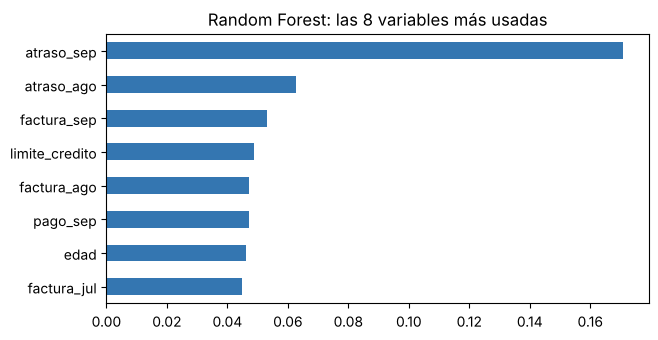

In [17]:
bosque = evaluar('Random Forest (200 árboles)', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1))

# ¿Qué columnas usó más?
importancia = pd.Series(bosque.feature_importances_, index=X.columns).sort_values()
importancia.tail(8).plot(kind='barh', figsize=(7, 3.5), color='#3476B1', title='Random Forest: las 8 variables más usadas')
plt.show()

**Lectura:** el bosque sube a **0.78** de AUC en Validation, por encima de cualquier árbol solo. La variable más usada es `atraso_sep`, seguida de los otros atrasos y de los montos de facturas y pagos. Recuerda: importancia **predictiva**, no causal.

# 5. Bagging frente a boosting (1.4)

Las dos son formas de **combinar muchos modelos débiles** para obtener uno fuerte. La diferencia está en cómo se organizan.

| | Bagging | Boosting |
|---|---|---|
| Imagen | un **comité**: muchos expertos opinan por separado y se promedia | una **cadena de correctores**: cada uno revisa los errores del anterior |
| Cómo entrenan | en paralelo, cada uno con una muestra sorteada | en fila, uno después de otro |
| Cada modelo | árbol grande (sabe mucho, pero es inestable) | árbol pequeño (sabe poco, pero es estable) |
| Qué reduce | la **varianza** (la inestabilidad) | el **sesgo** (lo que el modelo simple no alcanza a ver) |
| Riesgo | casi no sobreajusta al añadir árboles | **sí puede sobreajustar** si se añaden demasiados |
| Ejemplo | Random Forest | Gradient Boosting, XGBoost, LightGBM |

Random Forest **es** bagging de árboles, más el sorteo de columnas.

## 5.1 Boosting a mano

Tomemos el dato más simple: la tasa de impago según los meses de atraso (parte 1.1). Queremos aproximar esa curva usando solo **tocones**: árboles con una única pregunta, que solo pueden dibujar un escalón.

El procedimiento del boosting:

1. Empezar con una predicción simple: el promedio.
2. Calcular el **residuo**: lo que le falta a la predicción para llegar al dato.
3. Entrenar un tocón **para predecir el residuo**.
4. Sumar ese tocón a la predicción. Volver al paso 2.

Ronda 0 · error medio absoluto = 0.255
Ronda 1 · el tocón pregunta: ¿atraso <= 1.5? · error medio absoluto = 0.066
Ronda 2 · el tocón pregunta: ¿atraso <= 0.5? · error medio absoluto = 0.051
Ronda 3 · el tocón pregunta: ¿atraso <= 3.5? · error medio absoluto = 0.037


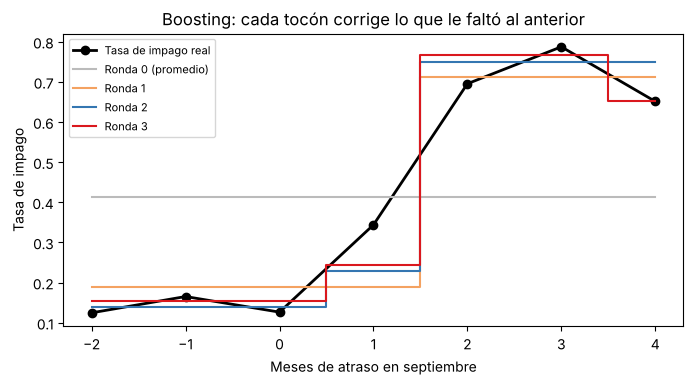

In [18]:
# Tasa de impago por meses de atraso (de -2 a 4), calculada con Train
tasas = y_train.groupby(X_train['atraso_sep']).mean().loc[-2:4]
atraso = tasas.index.values.reshape(-1, 1)
tasa = tasas.values

prediccion = np.full(len(tasa), tasa.mean())      # paso 1: empezamos con el promedio
historial = {'Ronda 0 (promedio)': prediccion.copy()}
print(f'Ronda 0 · error medio absoluto = {np.abs(tasa - prediccion).mean():.3f}')

for ronda in [1, 2, 3]:
    residuo = tasa - prediccion                                         # paso 2: lo que falta
    tocon = DecisionTreeRegressor(max_depth=1).fit(atraso, residuo)     # paso 3: un tocón aprende el residuo
    prediccion = prediccion + tocon.predict(atraso)                     # paso 4: lo sumamos
    historial[f'Ronda {ronda}'] = prediccion.copy()
    print(f'Ronda {ronda} · el tocón pregunta: ¿atraso <= {tocon.tree_.threshold[0]:.1f}? · error medio absoluto = {np.abs(tasa - prediccion).mean():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tasas.index, tasa, 'ko-', linewidth=2, label='Tasa de impago real')
for (nombre, valores), color in zip(historial.items(), ['#BBBBBB', '#F4A261', '#3476B1', '#DA181E']):
    ax.step(tasas.index, valores, where='mid', color=color, label=nombre)
ax.set_xlabel('Meses de atraso en septiembre'); ax.set_ylabel('Tasa de impago'); ax.legend(fontsize=8)
ax.set_title('Boosting: cada tocón corrige lo que le faltó al anterior')
plt.show()

**Lectura:** la ronda 0 es una línea plana (el promedio) y se equivoca mucho. El primer tocón pregunta "¿atraso ≤ 1.5?" y dibuja un solo escalón: es, otra vez, la regla del atraso. El segundo y el tercero añaden escalones donde quedaba más error. **Con tres preguntas simples encadenadas, el error baja a menos de la quinta parte.**

Eso es boosting: ningún tocón es bueno por sí solo, pero cada uno arregla lo que el anterior dejó mal. En la práctica, cada corrección se multiplica por una **tasa de aprendizaje** pequeña (por ejemplo 0.1) para avanzar con pasos cortos y no pasarse. Guarda esa idea: la volveremos a ver, casi idéntica, en el descenso del gradiente de la Unidad 3.

## 5.2 Los dos métodos con los 18 000 clientes

- **Bagging**: 100 árboles sin límite de profundidad, cada uno con una muestra sorteada.
- **Boosting**: 100 árboles de profundidad 3, en fila, con tasa de aprendizaje 0.1.

In [19]:
evaluar('Bagging (100 árboles grandes)', BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=42, n_jobs=-1))
boosting = evaluar('Boosting (100 árboles pequeños)', GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42))

Bagging (100 árboles grandes)          AUC Train = 1.000 · AUC Validation = 0.768


Boosting (100 árboles pequeños)        AUC Train = 0.812 · AUC Validation = 0.781


**Lectura:** mira la columna de Train. El bagging tiene AUC 1.000 en Train (cada árbol memoriza) y aun así generaliza bien, 0.77, porque **promediar cancela la memoria** de cada árbol. El boosting tiene 0.81 en Train y **0.78** en Validation: aprende menos de memoria y generaliza un poco mejor.

## 5.3 ¿Qué pasa al añadir más árboles?

Medimos el AUC en Validation a medida que crece el número de árboles.

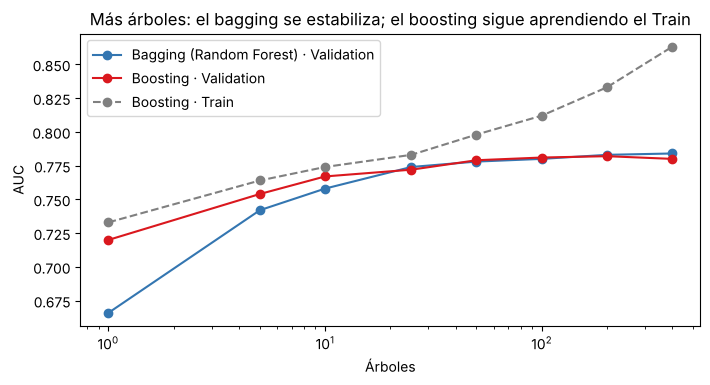

,Bagging (Random Forest) · Validation,Boosting · Validation,Boosting · Train
Árboles,,,
1,0.666,0.720,0.733
5,0.742,0.754,0.764
10,0.758,0.767,0.774
25,0.774,0.772,0.783
50,0.778,0.779,0.798
100,0.780,0.781,0.812
200,0.783,0.782,0.833
400,0.784,0.780,0.863


In [20]:
cantidades = [1, 5, 10, 25, 50, 100, 200, 400]

# Boosting: staged_predict_proba devuelve la predicción después de cada árbol, sin reentrenar
boosting_largo = GradientBoostingClassifier(n_estimators=400, max_depth=3, learning_rate=0.1, random_state=42).fit(X_train, y_train)
etapas_val = [roc_auc_score(y_val, p[:, 1]) for p in boosting_largo.staged_predict_proba(X_val)]
etapas_train = [roc_auc_score(y_train, p[:, 1]) for p in boosting_largo.staged_predict_proba(X_train)]

# Bagging: Random Forest con cada cantidad de árboles
bagging_val = []
for cantidad in cantidades:
    rf = RandomForestClassifier(n_estimators=cantidad, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_train, y_train)
    bagging_val.append(roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]))

curva = pd.DataFrame({
    'Bagging (Random Forest) · Validation': bagging_val,
    'Boosting · Validation': [etapas_val[c - 1] for c in cantidades],
    'Boosting · Train': [etapas_train[c - 1] for c in cantidades],
}, index=pd.Index(cantidades, name='Árboles')).round(3)

ax = curva.plot(marker='o', figsize=(8, 3.8), color=['#3476B1', '#DA181E', 'gray'], style=['-', '-', '--'])
ax.set_xscale('log'); ax.set_ylabel('AUC'); ax.set_title('Más árboles: el bagging se estabiliza; el boosting sigue aprendiendo el Train')
plt.show()
curva

**Lectura:**

- **Bagging**: con 1 árbol es malo; sube rápido y **se estabiliza** cerca de 0.78. Añadir árboles nunca lo empeora: solo cuesta tiempo.
- **Boosting**: con pocos árboles ya es competitivo; alcanza su mejor valor en Validation alrededor de 100 a 200 árboles y después **deja de mejorar, mientras el Train sigue subiendo**. Esa separación es sobreajuste: en boosting, el número de árboles **sí** es un hiperparámetro que hay que validar.

# 6. Comparación: ¿cuál escoger? (1.5)

Todos los modelos de la unidad, medidos en la misma Validation.

In [21]:
comparacion = pd.DataFrame(resultados).T.sort_values('AUC', ascending=False)
comparacion.round(3)

,Exactitud,Precisión,Sensibilidad,F1,AUC,Segundos
Random Forest (200 árboles),0.820,0.672,0.360,0.469,0.783,4.802
Boosting (100 árboles pequeños),0.822,0.686,0.356,0.469,0.781,5.921
Bagging (100 árboles grandes),0.815,0.645,0.362,0.464,0.768,12.768
Árbol profundidad 5,0.820,0.683,0.348,0.461,0.753,0.121
KNN k=25,0.813,0.658,0.324,0.434,0.746,1.299
KNN k=25 ponderado por distancia,0.811,0.642,0.325,0.431,0.745,1.267
SVM kernel RBF (5 000 clientes),0.818,0.681,0.332,0.447,0.728,2.473
Árbol profundidad 2,0.816,0.693,0.305,0.424,0.690,0.052
Base: atraso de 2+ meses,0.816,0.683,0.313,0.430,0.683,0.000
KNN k=25 sin escalar,0.776,0.463,0.085,0.144,0.646,5.871


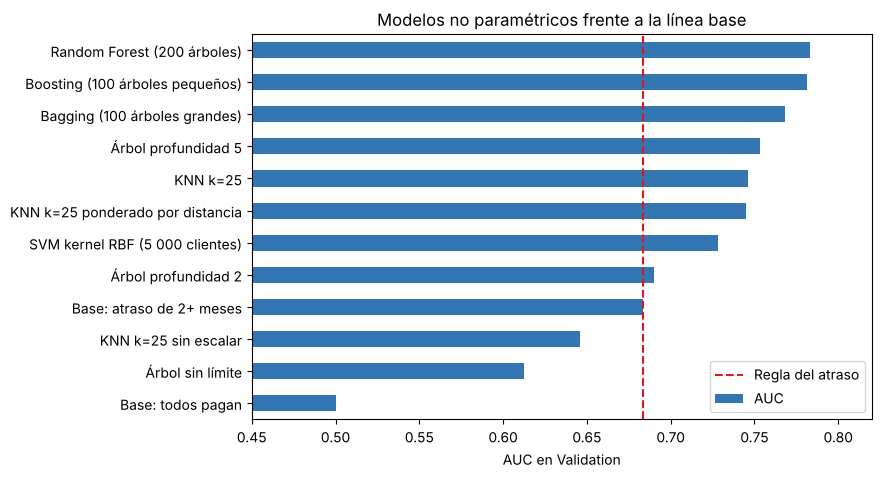

In [22]:
ax = comparacion['AUC'].sort_values().plot(kind='barh', figsize=(8, 5), color='#3476B1')
ax.axvline(resultados['Base: atraso de 2+ meses']['AUC'], color='#DA181E', linestyle='--', label='Regla del atraso')
ax.set_xlim(0.45, 0.82); ax.set_xlabel('AUC en Validation'); ax.legend()
ax.set_title('Modelos no paramétricos frente a la línea base')
plt.show()

### Lectura

| Lugar | Modelo | AUC Validation | Comentario |
|---|---|---:|---|
| 1 | Random Forest | ≈ 0.78 | El mejor, empatado con el boosting |
| 2 | Boosting | ≈ 0.78 | Mismo nivel con árboles mucho más pequeños |
| 3 | Bagging | ≈ 0.77 | Como el bosque, sin el sorteo de columnas |
| 4 | Árbol de profundidad 5 | ≈ 0.75 | Casi tan bueno, instantáneo y legible |
| 5 | KNN (k = 25, escalado) | ≈ 0.75 | Bueno, pero lento al predecir |
| 6 | SVM con kernel RBF | ≈ 0.73 | Entrenado con una muestra de 5 000 |
| — | Regla del atraso | 0.68 | La línea base |
| — | Árbol sin límite, KNN sin escalar | < 0.68 | **Peores que la regla**: uno memorizó, el otro midió mal las distancias |

Tres ideas:

1. **Los conjuntos de árboles ganan** en datos tabulares como estos. Es lo habitual.
2. **La distancia entre modelos es pequeña** (0.75 a 0.78) comparada con la distancia a la línea base (0.68). Elegir bien las variables y validar bien importa más que el algoritmo.
3. Mira la sensibilidad: los mejores modelos detectan solo entre el 30 % y el 36 % de los impagos. ¿Por qué? Porque clasifican como impago solo si la probabilidad supera 0.5. **Ese umbral es una decisión, no un dato**: lo trabajaremos en la Unidad 2 (probabilidades) y en la Unidad 4 (costos de cada error).

### Guía rápida de elección

| Si necesitas... | Usa | Porque |
|---|---|---|
| Explicar la decisión a un comité | Árbol pequeño | Son reglas que se leen |
| El mejor resultado sin ajustar mucho | Random Forest | Robusto; casi no sobreajusta al añadir árboles |
| Exprimir el último punto de rendimiento | Boosting | Suele ganar, pero hay que validar árboles y tasa de aprendizaje |
| Pocos datos y pocas columnas | KNN o kernel | Simples; siempre escalando |
| Muchísimas filas y respuesta inmediata | Evita KNN | Guarda todo el Train y compara contra todos |
| Probabilidades bien calibradas e incertidumbre | **Modelos bayesianos** | Unidad 2 |
| Relaciones muy complejas y muchos datos | **Redes neuronales** | Unidad 3 |

# Para pensar antes de la Unidad 2

La regla del atraso dice: "si tiene 2 o más meses de atraso, impaga". En Validation acertó en el 68 % de sus alertas. Es decir:

> De los clientes con 2 o más meses de atraso, el 68 % impaga.

Ahora la pregunta al revés: **de los clientes que impagan, ¿qué porcentaje tenía 2 o más meses de atraso?** Ya vimos la respuesta: el 31 % (la sensibilidad).

Son dos preguntas distintas con dos respuestas distintas, y confundirlas es uno de los errores más frecuentes al interpretar datos. Pasar de una a la otra es exactamente lo que hace el **teorema de Bayes**.

## Checklist de la unidad

- [ ] ¿Sé por qué la exactitud engaña cuando hay 22 % de impagos?
- [ ] ¿Escalé antes de usar un modelo que mide distancias?
- [ ] ¿Puedo explicar la diferencia entre k pequeño y k grande?
- [ ] ¿Puedo explicar qué es un kernel con la frase "vecinos que pesan según su cercanía"?
- [ ] ¿Puedo explicar bagging como un comité y boosting como una cadena de correctores?
- [ ] ¿Comparé cada modelo con la línea base en la misma Validation?
- [ ] ¿Dejé el Test sin tocar?